In [1]:
# =========================================================
# RPDA8412 RESEARCH PROJECT
# NOTEBOOK 05: EXPLORATORY DATA ANALYSIS
# =========================================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FINAL_DIR = PROJECT_ROOT / "data" / "final"
FIGURES_DIR = PROJECT_ROOT / "figures"
TABLES_DIR = PROJECT_ROOT / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    FINAL_DIR / "daily_volatility_engineered_provisional.csv",
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

display(df.head())

EXPLORATORY DATA ANALYSIS
Dataset shape: (4024, 15)
Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00

Columns:
['Date', 'Adj_Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'GPR_lag1', 'EPU_lag1', 'Log_Return', 'Squared_Return', 'RV_Historical_20D', 'RV_Future_1D', 'RV_Future_5D', 'RV_Future_20D']

Missing values:
Date                  0
Adj_Close             0
Close                 0
High                  0
Low                   0
Open                  0
Volume                0
GPR_lag1              0
EPU_lag1              0
Log_Return            1
Squared_Return        1
RV_Historical_20D    20
RV_Future_1D          1
RV_Future_5D          5
RV_Future_20D        20
dtype: int64


,Date,Adj_Close,Close,High,Low,Open,Volume,GPR_lag1,EPU_lag1,Log_Return,Squared_Return,RV_Historical_20D,RV_Future_1D,RV_Future_5D,RV_Future_20D
0,2010-01-04,1132.989990,1132.989990,1133.869995,1116.560059,1116.560059,3991400000,91.471298,216.95,NaN,NaN,NaN,0.003111,0.006103,0.046068
1,2010-01-05,1136.520020,1136.520020,1136.630005,1129.660034,1132.660034,2491020000,177.117065,150.35,0.003111,9.677276e-06,NaN,0.000545,0.010789,0.046290
2,2010-01-06,1137.140015,1137.140015,1139.189941,1133.949951,1135.709961,4972660000,122.525620,151.16,0.000545,2.974305e-07,NaN,0.003993,0.013596,0.056065
3,2010-01-07,1141.689941,1141.689941,1142.459961,1131.319946,1136.270020,5270680000,161.588669,95.95,0.003993,1.594579e-05,NaN,0.002878,0.013221,0.055997
4,2010-01-08,1144.979980,1144.979980,1145.390015,1136.219971,1140.520020,4389590000,102.262291,92.20,0.002878,8.280484e-06,NaN,0.001745,0.016880,0.056627


In [11]:
# =========================================================
# DESCRIPTIVE STATISTICS
# =========================================================

variables = [
    "Close",
    "Log_Return",
    "RV_Historical_20D",
    "RV_Future_1D",
    "RV_Future_5D",
    "RV_Future_20D",
    "GPR_lag1",
    "EPU_lag1"
]

descriptive_stats = df[variables].describe().T

descriptive_stats["Skewness"] = df[variables].skew()
descriptive_stats["Kurtosis"] = df[variables].kurt()

display(descriptive_stats.round(6))

# Save table
descriptive_stats.to_csv(
    TABLES_DIR / "descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully!")

,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
Close,4024.0,2945.011381,1491.073720,1022.580017,1805.630035,2584.730103,4078.204956,6932.049805,0.775638,-0.332749
Log_Return,4023.0,0.000447,0.010942,-0.127652,-0.003811,0.000702,0.005675,0.090895,-0.614741,13.573547
RV_Historical_20D,4004.0,0.041530,0.026071,0.009526,0.026326,0.035147,0.049002,0.270908,3.805565,24.513567
RV_Future_1D,4023.0,0.007225,0.008229,0.000000,0.001973,0.004837,0.009742,0.127652,3.840307,29.810868
RV_Future_5D,4019.0,0.019598,0.014697,0.001362,0.010600,0.016385,0.024053,0.200982,4.049536,31.895974
RV_Future_20D,4004.0,0.041530,0.026071,0.009526,0.026326,0.035147,0.049002,0.270908,3.805565,24.513567
GPR_lag1,4024.0,106.215976,51.519556,0.000000,71.635078,97.428459,130.606281,540.827393,1.725402,7.265628
EPU_lag1,4024.0,147.749292,115.585078,4.050000,76.570000,113.010000,174.700000,1026.380000,2.395755,7.692568


Descriptive statistics saved successfully!


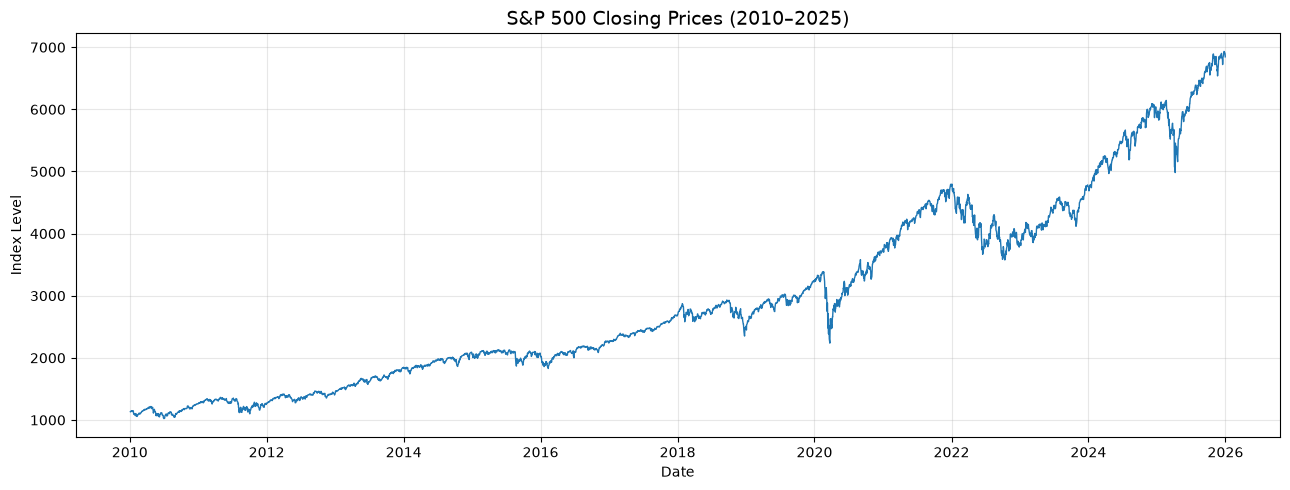

In [3]:
# =========================================================
# FIGURE 1: S&P 500 CLOSING PRICES
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    df["Close"],
    linewidth=1
)

plt.title(
    "S&P 500 Closing Prices (2010–2025)",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Index Level")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sp500_closing_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

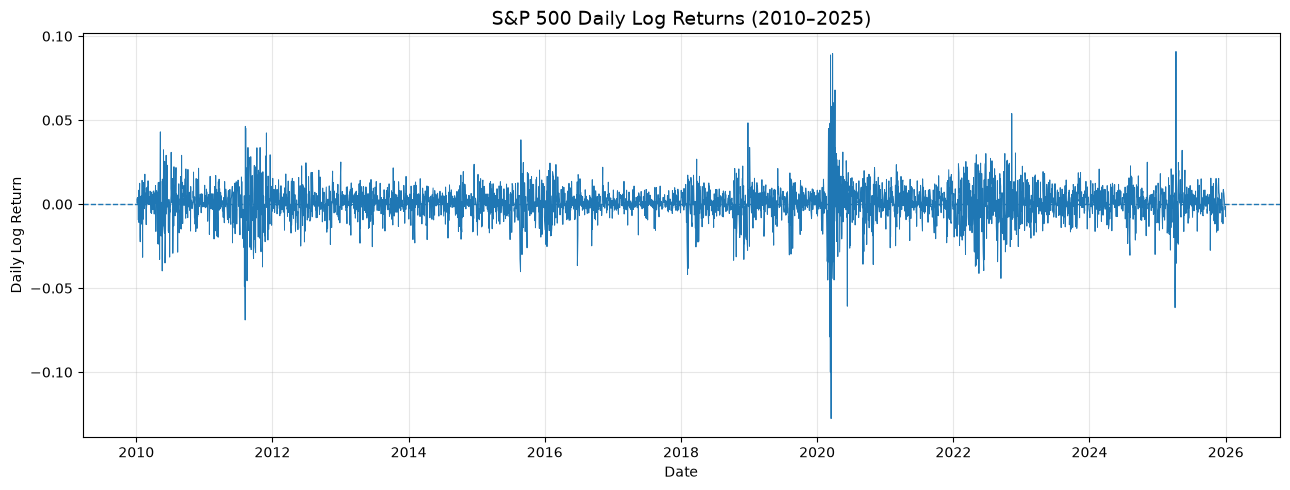

In [4]:
# =========================================================
# FIGURE 2: DAILY LOG RETURNS
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    df["Log_Return"],
    linewidth=0.7
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "S&P 500 Daily Log Returns (2010–2025)",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Daily Log Return")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sp500_daily_log_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

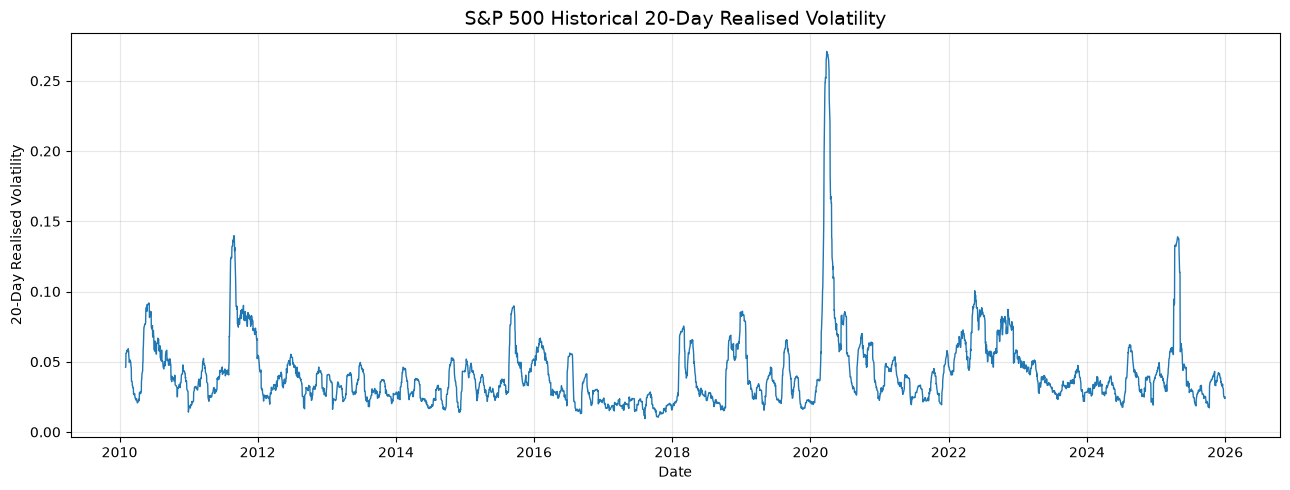

In [5]:
# =========================================================
# FIGURE 3: HISTORICAL 20-DAY REALISED VOLATILITY
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    df["RV_Historical_20D"],
    linewidth=1
)

plt.title(
    "S&P 500 Historical 20-Day Realised Volatility",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("20-Day Realised Volatility")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sp500_historical_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

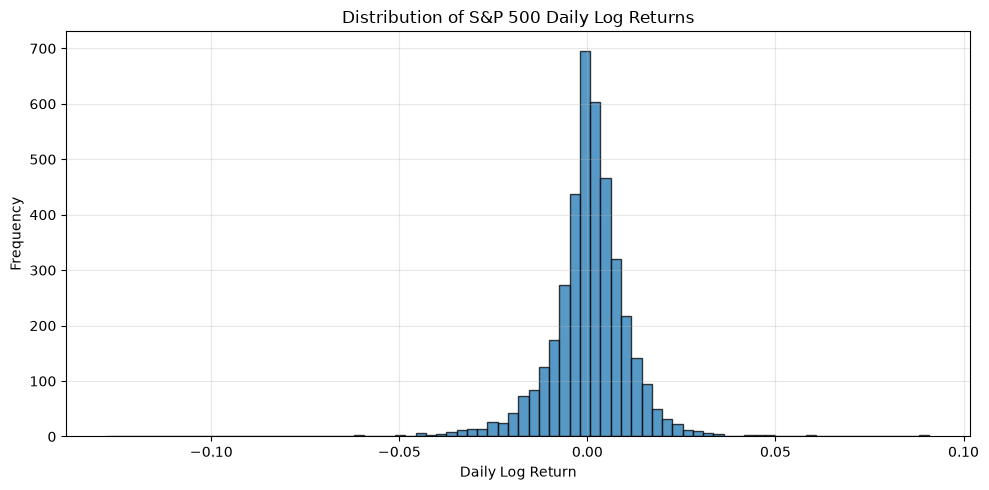

In [6]:
# =========================================================
# FIGURE 4: DISTRIBUTION OF DAILY LOG RETURNS
# =========================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["Log_Return"].dropna(),
    bins=80,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of S&P 500 Daily Log Returns")

plt.xlabel("Daily Log Return")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "log_return_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

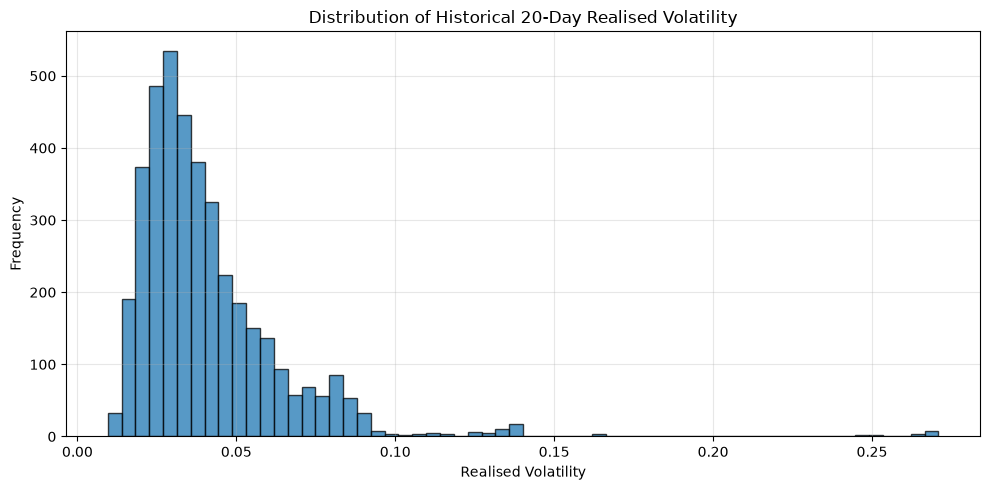

In [7]:
# =========================================================
# FIGURE 5: DISTRIBUTION OF REALISED VOLATILITY
# =========================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["RV_Historical_20D"].dropna(),
    bins=60,
    edgecolor="black",
    alpha=0.75
)

plt.title(
    "Distribution of Historical 20-Day Realised Volatility"
)

plt.xlabel("Realised Volatility")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "realised_volatility_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# =========================================================
# CORRELATION ANALYSIS
# =========================================================

correlation_variables = [
    "RV_Historical_20D",
    "RV_Future_1D",
    "RV_Future_5D",
    "RV_Future_20D",
    "GPR_lag1",
    "EPU_lag1"
]

correlation_matrix = df[
    correlation_variables
].corr()

print("=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

display(correlation_matrix.round(4))

correlation_matrix.to_csv(
    TABLES_DIR / "correlation_matrix.csv"
)

CORRELATION MATRIX


,RV_Historical_20D,RV_Future_1D,RV_Future_5D,RV_Future_20D,GPR_lag1,EPU_lag1
RV_Historical_20D,1.0000,0.4477,0.6014,0.5196,0.0157,0.3954
RV_Future_1D,0.4477,1.0000,0.6800,0.4990,0.0096,0.1681
RV_Future_5D,0.6014,0.6800,1.0000,0.7726,0.0042,0.2299
RV_Future_20D,0.5196,0.4990,0.7726,1.0000,0.0112,0.2184
GPR_lag1,0.0157,0.0096,0.0042,0.0112,1.0000,0.0097
EPU_lag1,0.3954,0.1681,0.2299,0.2184,0.0097,1.0000


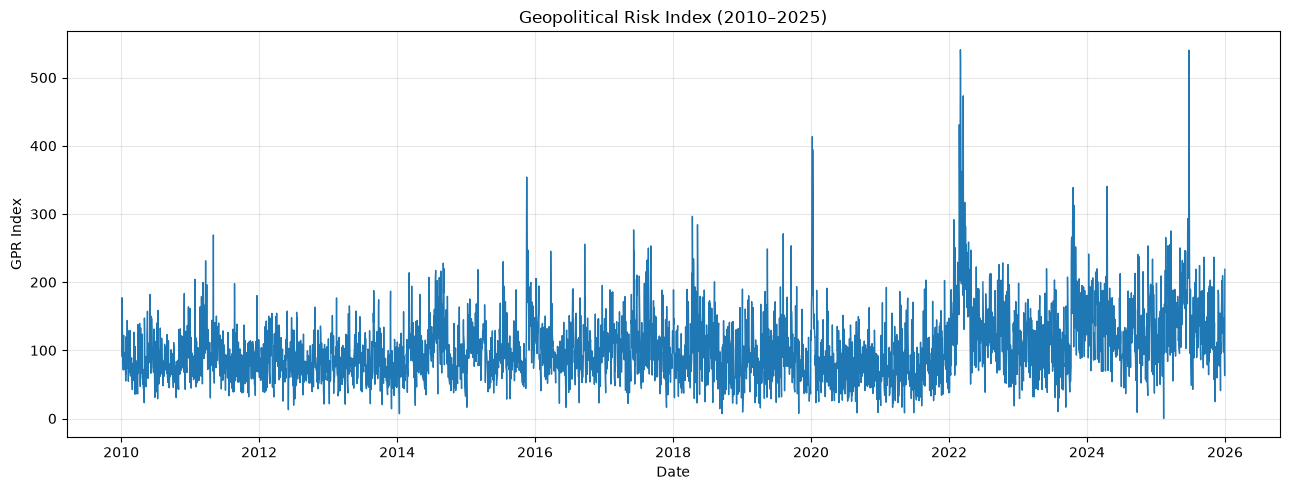

In [9]:
# =========================================================
# FIGURE 6: GEOPOLITICAL RISK
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    df["GPR_lag1"],
    linewidth=1
)

plt.title(
    "Geopolitical Risk Index (2010–2025)"
)

plt.xlabel("Date")
plt.ylabel("GPR Index")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gpr_daily.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

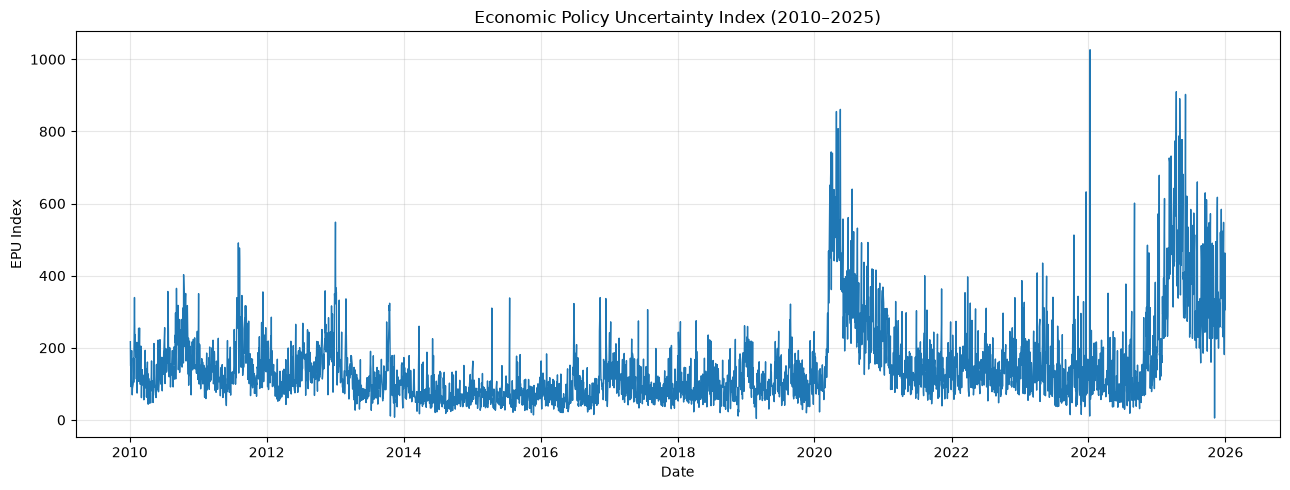

In [10]:
# =========================================================
# FIGURE 7: ECONOMIC POLICY UNCERTAINTY
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    df["Date"],
    df["EPU_lag1"],
    linewidth=1
)

plt.title(
    "Economic Policy Uncertainty Index (2010–2025)"
)

plt.xlabel("Date")
plt.ylabel("EPU Index")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "epu_daily.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()